In [1]:
import torch

x1, x2, y = 2.0, 1.0, 5.0
w1 = torch.tensor(0.5, requires_grad=True)
w2 = torch.tensor(1.0, requires_grad=True)
w3 = torch.tensor(1.5, requires_grad=True)

z = w1 * x1 + w2 * x2
h = torch.relu(z)
y_hat = w3 * h
loss = (y_hat - y) ** 2

loss.backward()

print("y_hat:", y_hat.item(), " loss:", loss.item())
print("blame w1:", w1.grad.item(), " w2:", w2.grad.item(), " w3:", w3.grad.item())

y_hat: 3.0  loss: 4.0
blame w1: -12.0  w2: -6.0  w3: -8.0


In [2]:
opt = torch.optim.SGD([w1, w2, w3], lr=0.01)
opt.step()

print("new weights:", round(w1.item(), 2), round(w2.item(), 2), round(w3.item(), 2))

y_hat_new = w3 * torch.relu(w1 * x1 + w2 * x2)
loss_new = (y_hat_new - y) ** 2
print("new y_hat:", round(y_hat_new.item(), 2), " new loss:", round(loss_new.item(), 2))

new weights: 0.62 1.06 1.58
new y_hat: 3.63  new loss: 1.87


## Sanity check: autograd vs. hand calculation
A tiny 2-1-1 ReLU network (x = [2, 1], y = 5). PyTorch's `loss.backward()` gives the
same gradients as my hand calculation (w1: -12, w2: -6, w3: -8), and one SGD step with
lr = 0.01 lowers the loss from 4.0 to 1.87, exactly as computed by hand.

In [3]:
import pandas as pd
import numpy as np

url = "http://archive.ics.uci.edu/ml/machine-learning-databases/auto-mpg/auto-mpg.data"
column_names = ["MPG", "Cylinders", "Displacement", "Horsepower", "Weight",
                "Acceleration", "Model Year", "Origin"]
df = pd.read_csv(url, names=column_names, na_values="?", comment="\t",
                 sep=" ", skipinitialspace=True).dropna()
df["Origin"] = df["Origin"].map({1: "USA", 2: "Europe", 3: "Japan"})
df = pd.get_dummies(df, prefix="", prefix_sep="", dtype="float32")

df_train = df.sample(frac=0.8, random_state=0)
df_test = df.drop(df_train.index)
X_train, X_test = df_train.drop(columns="MPG"), df_test.drop(columns="MPG")
y_train, y_test = df_train["MPG"], df_test["MPG"]

In [6]:
mean = X_train.mean()
std = X_train.std()

X_train_s = (X_train - mean) / std
X_test_s = (X_test - mean) / std

In [7]:
import torch

X_tr = torch.tensor(X_train_s.values, dtype=torch.float32)
X_te = torch.tensor(X_test_s.values, dtype=torch.float32)
y_tr = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
y_te = torch.tensor(y_test.values, dtype=torch.float32).reshape(-1, 1)

print(X_tr.shape, y_tr.shape)

torch.Size([314, 9]) torch.Size([314, 1])


In [8]:
import torch.nn as nn

torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(9, 64),
    nn.GELU(),
    nn.Linear(64, 64),
    nn.GELU(),
    nn.Linear(64, 1),
)

n_params = sum(p.numel() for p in model.parameters())
print(n_params)

4865


In [9]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [10]:
n_fit = int(len(X_tr) * 0.8)
X_fit, y_fit = X_tr[:n_fit], y_tr[:n_fit]
X_val, y_val = X_tr[n_fit:], y_tr[n_fit:]

history = {"loss": [], "val_loss": []}

for epoch in range(100):
    model.train()
    perm = torch.randperm(n_fit)
    for i in range(0, n_fit, 32):
        idx = perm[i:i + 32]
        y_hat = model(X_fit[idx])
        loss = loss_fn(y_hat, y_fit[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        history["loss"].append(loss_fn(model(X_fit), y_fit).item())
        history["val_loss"].append(loss_fn(model(X_val), y_val).item())

print(len(X_fit), len(X_val))
print(round(history["loss"][-1], 2), round(history["val_loss"][-1], 2))

251 63
1.73 2.22


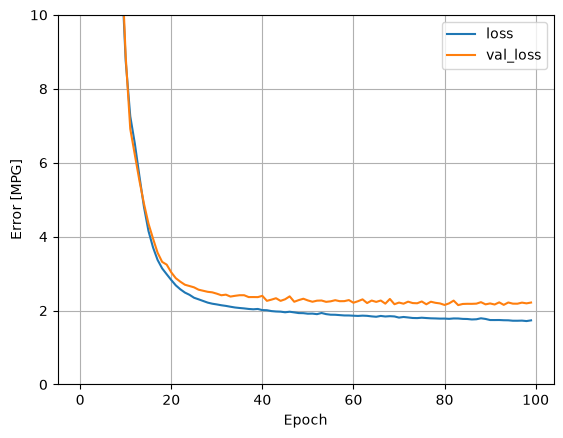

test MAE: 1.72


In [11]:
import matplotlib.pyplot as plt

plt.plot(history["loss"], label="loss")
plt.plot(history["val_loss"], label="val_loss")
plt.ylim([0, 10])
plt.xlabel("Epoch")
plt.ylabel("Error [MPG]")
plt.legend()
plt.grid(True)
plt.show()

model.eval()
with torch.no_grad():
    test_mae = loss_fn(model(X_te), y_te).item()
print("test MAE:", round(test_mae, 2))

In [12]:
torch.save(model.state_dict(), "mpg_pytorch.pt")

In [13]:
from datetime import date

checkpoint = {
    "state_dict": model.state_dict(),
    "mean": torch.tensor(mean.values, dtype=torch.float32),
    "std": torch.tensor(std.values, dtype=torch.float32),
    "columns": list(X_train.columns),
}
filename = f"mpg_pytorch_{date.today()}_mae{test_mae:.2f}.pt"
torch.save(checkpoint, filename)
print(filename)

mpg_pytorch_2026-11-01_mae1.72.pt


# Auto MPG regression in PyTorch
Rebuilding the Keras model from notebook 01 (9 inputs, two Dense(64) GELU layers, MAE loss, Adam)
with a hand-written PyTorch training loop.

**Result:** test MAE 1.72 MPG (Keras: 1.65, linear regression: 2.39). The gap between the two
libraries is within run-to-run noise.